# Beam pattern and angle-delay maps under hardware impairments

Reproduces Fig. 1 and Fig. 2 of the paper (Examples 1 and 2, Sec. II-D). An ISAC BS with $K = 64$ antennas per ULA is affected by gain-phase (GPIs) and antenna displacement impairments (ADIs), eq. (11). Two cases are compared:
- **Impairment knowledge**: the TX precoder and the RX angle dictionary use the true impairments $\Xi$.
- **No impairment knowledge**: they use the ideal ULA (unit gains, $\lambda/2$ spacing), while the channel still contains $\Xi$.

**Fig. 1**: response $|\boldsymbol{a}_{\rm tx}^\top(\vartheta)\boldsymbol{f}|^2$ of the ISAC precoder in (10) with $\omega_r = 0.75$, $P = 0.1$ W, and $\boldsymbol{f}_s$, $\boldsymbol{f}_c$ from (13) for the sectors $[-40^\circ, -20^\circ]$ (sensing) and $[30^\circ, 40^\circ]$ (communication).

**Fig. 2**: ADMs of five targets during the OMP algorithm (Algorithm 1, Sec. III-B), normalized to the maximum of the first ADM with impairment knowledge. Fig. 2a is the first iteration and Fig. 2b is the residual after the five targets have been removed.

The notebook is self-contained and runs on CPU. It saves the beam patterns (`beam_ideal.txt`, `beam_hwi.txt`) and the ADMs of Fig. 2 (`first_it_*.pdf`, `residual_*.pdf`) in the working directory.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import rc

rc('font', **{'family': 'serif'})

# Fix the seeds: the impairment, target and noise realizations are those of Figs. 1 and 2
seed_num = 0
torch.manual_seed(seed_num)
np.random.seed(seed_num)
torch.cuda.manual_seed(seed_num)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

device = 'cpu'

## Functions

In [2]:
def generateUniform(min_val, max_val, out_shape, rng_gen=None, device='cpu'):
    '''Samples from U[min_val, max_val) with shape out_shape.'''
    return torch.rand(out_shape, generator=rng_gen, device=device) * (max_val - min_val) + min_val

def generateGPImpairments(min_gain, max_gain, min_phase, max_phase, numAntennas, rng_gen=None, device='cpu'):
    '''GPIs gamma_x in (11) with uniform gain and phase, normalized to ||gamma_x||^2 = K (ideal ULA). Shape: (K, 1).'''
    gain = generateUniform(min_gain, max_gain, (numAntennas,1), rng_gen, device)
    phase = generateUniform(min_phase, max_phase, (numAntennas,1), rng_gen, device)
    gain_phase = gain*torch.exp(1j*phase)
    gain_phase *= np.sqrt(numAntennas)/torch.norm(gain_phase)
    return gain_phase

def generateImpairedPosUniform(eta, numAntennas, lamb, initial_pos_ula, rng_gen=None, device='cpu'):
    '''Antenna positions p_x = p_ideal + eps_p with [eps_p]_k ~ U[-eta, eta] (Sec. IV-A). Shape: (K,).'''
    lamb_2_pos = initial_pos_ula + lamb/2.0 * torch.arange(0,numAntennas, device=device)
    disturbance = eta*(2*torch.rand(lamb_2_pos.shape, generator=rng_gen, device=device) - 1)
    return lamb_2_pos + disturbance

def steeringMatrix(theta_min, theta_max, pos, lamb, gp_error=None, rng_gen=None):
    '''Steering vectors in (11) for angles drawn from U[theta_min, theta_max) (theta_min = theta_max for given angles).
    Outputs: steering vectors as columns (K, N) and angles (N, 1).
    '''
    if gp_error == None:
        gp_error = torch.ones((len(pos),1), dtype=torch.cfloat, device = pos.device)
    theta = generateUniform(theta_min, theta_max, theta_min.shape, rng_gen=rng_gen, device=theta_min.device)
    theta = theta.view(1, -1)
    matrix = gp_error * torch.exp(-1j * 2 * np.pi / lamb * pos.view(-1,1).type(torch.cfloat) @ torch.sin(theta.type(torch.cfloat)))
    return matrix, theta.view(-1,1)

def delayMatrix(r_min, r_max, delta_f, S, rng_gen=None):
    '''Frequency-domain steering vectors rho(tau) in (4) for ranges drawn from U[r_min, r_max) (r_min = r_max for given ranges).
    Outputs: steering vectors as columns (S, N) and ranges (N, 1).
    '''
    device = r_min.device
    range_tgt = generateUniform(r_min, r_max, r_min.shape, rng_gen, device=device)
    range_tgt = range_tgt.view(1, -1)
    matrix = torch.exp(-1j*2*np.pi*delta_f * 2/3e8 * torch.arange(0,S, device=device).view(-1,1).type(torch.cfloat) @ range_tgt.type(torch.cfloat))
    return matrix, range_tgt.view(-1,1)

def generateInterval(mean_min, mean_max, span_min, span_max, batch_size=1, rng_gen=None, device='cpu'):
    '''Interval [mean - span/2, mean + span/2] with mean ~ U[mean_min, mean_max) and span ~ U[span_min, span_max). Shapes: (batch_size, 1).'''
    mean = generateUniform(mean_min, mean_max, (batch_size, 1), rng_gen, device=device)
    span = generateUniform(span_min, span_max, (batch_size, 1), rng_gen, device=device)
    return mean - span / 2.0, mean + span / 2.0

def uniformGrid(v_min, v_max, n_grid):
    '''n_grid uniformly spaced points in [v_min, v_max] per batch sample. Shape: (batch_size, n_grid).'''
    delta = (v_max - v_min)/(n_grid - 1)
    return v_min + delta*torch.arange(n_grid, device=v_min.device).reshape(1,-1)

def createPrecoder(theta_min, theta_max, A_matrix, Ngrid=256, P=None, device='cpu'):
    '''Sector precoder f_x in (13): normalized sum of the conjugate steering vectors (columns of A_matrix, on a
    uniform grid in [-pi/2, pi/2]) inside [theta_min, theta_max]. If the sector contains no grid angle, the closest one is used.
    Outputs: precoder (batch_size, K, 1) with ||f_x||^2 = P and sector indicator (batch_size, 1, Ngrid).
    '''
    if P==None:
        P = torch.tensor(1.0, dtype=torch.float32, device=device)
    batch_size = theta_min.shape[0] if theta_min.dim()>0 else 1
    angle_vector = torch.linspace(-np.pi/2, np.pi/2, Ngrid, device = device).reshape(1,-1)
    b_vec = ((angle_vector >= theta_min) & (angle_vector <= theta_max))*1.0
    zero_indices = b_vec.sum(dim=1) == 0
    diff = torch.abs(theta_min - angle_vector)
    min_indices = torch.argmin(diff, dim=1)
    b_vec[zero_indices, min_indices[zero_indices]] = 1.0
    b_vec = b_vec.type(torch.cfloat).reshape(batch_size, Ngrid, 1)
    precoder = A_matrix.conj() @ b_vec
    precoder_out = precoder * torch.sqrt(P) / torch.norm(precoder, dim=-2, keepdim=True)
    return precoder_out, b_vec.transpose(-1,-2)

def createCommonPrecoder(f_radar, f_comm, rho, phi, power=torch.tensor(1, device='cpu')):
    '''ISAC precoder f in (10) with trade-off rho = omega_r and extra phase phi on f_comm. Shape: (batch_size, K, 1).'''
    temp = torch.sqrt(rho) * f_radar + torch.sqrt(1-rho) * torch.exp(1j * phi) * f_comm
    return temp * torch.sqrt(power) / torch.norm(temp, dim=-2, keepdim=True)

def noise(var, dims, rng_gen=None, device='cpu'):
    '''Samples from CN(0, var) with shape dims.'''
    return torch.sqrt(var/2.0) * (torch.randn(dims, generator=rng_gen, device=device) + 1j * torch.randn(dims, generator=rng_gen, device=device))

def radarCH(mean_rcs, theta_min, theta_max, r_min, r_max, delta_f, K, gp_tx, gp_rx, pos_tx, pos_rx,
            lamb, S, f_precoder, x_msg, numTargets, noiseVariance_r, rng_gen=None, fix_psi = False,
            psi_value = None, fix_noise = False, noise_value = None):
    '''Clutter-free sensing observation Y_s in (1) with impairments (11), for numTargets[b] targets in batch sample b.
    Angles and ranges are drawn from [theta_min, theta_max) and [r_min, r_max), or given per target if min = max.
    The gains alpha_t follow (2) with Swerling-3 RCS and uniform phase, unless fix_psi (psi_value); the noise is
    CN(0, noiseVariance_r), unless fix_noise (noise_value). All targets are stacked along the batch dimension.
    Outputs: Y_s (batch_size, K, S), angles, ranges (sum(numTargets), 1), gains and noise.
    '''
    device = f_precoder.device
    batch_size_new = numTargets.sum()
    f_precoder = torch.repeat_interleave(f_precoder, numTargets, dim=0)     #Shape: (batch_size_new, K, 1)
    x_msg      = torch.repeat_interleave(x_msg, numTargets, dim=0)          #Shape: (batch_size_new, S, 1)
    if not torch.all(theta_min == theta_max):
        theta_min = torch.repeat_interleave(theta_min, numTargets, dim=0)
        theta_max = torch.repeat_interleave(theta_max, numTargets, dim=0)
    if not torch.all(r_min == r_max):
        r_min = torch.repeat_interleave(r_min, numTargets, dim=0)
        r_max = torch.repeat_interleave(r_max, numTargets, dim=0)

    # Delay steering vectors (4) and target ranges
    phase_shift, range_tgt = delayMatrix(r_min, r_max, delta_f, S, rng_gen)
    phase_shift = phase_shift.transpose(-1,-2).view(batch_size_new, S, 1)
    range_tgt = range_tgt.view(batch_size_new, 1, 1)

    # Complex channel gains (2)
    if fix_psi:
        psi = torch.clone(psi_value)
    else:
        rcs = torch.empty((batch_size_new,1,1), device=device).exponential_(lambd=1/mean_rcs, generator=rng_gen)
        phase_gain = generateUniform(0, 2*np.pi, (batch_size_new,1,1), rng_gen, device=device)
        mag_gain = torch.sqrt(rcs*lamb**2/((4*np.pi)**3*range_tgt**4))
        psi = mag_gain*torch.exp(1j*phase_gain)            #Shape: (batch_size_new, 1, 1)

    # Impaired TX and RX steering vectors (11)
    vector_tx, theta = steeringMatrix(theta_min, theta_max, pos_tx, lamb, gp_tx, rng_gen)
    vector_rx, _ = steeringMatrix(theta, theta, pos_rx, lamb, gp_rx, rng_gen)
    vector_tx = vector_tx.transpose(-1,-2).reshape(batch_size_new,K,1)
    vector_rx = vector_rx.transpose(-1,-2).reshape(batch_size_new,K,1)

    # Target reflections, summed over the targets of each batch sample
    reflection =  psi * vector_rx @ vector_tx.permute(0,2,1) @ f_precoder @ (x_msg * phase_shift).permute(0,2,1)
    batch_size = len(numTargets)
    ind = torch.arange(batch_size, device=device).repeat_interleave(numTargets)
    reflection_sum = torch.index_add(torch.zeros((batch_size,K,S), dtype=torch.cfloat, device=device),0,ind, reflection)

    if fix_noise:
        N = torch.clone(noise_value)
    else:
        N = noise(noiseVariance_r, reflection_sum.shape, rng_gen, device=device)
    Y = reflection_sum + N
    return Y, theta.view(-1,1), range_tgt.view(-1,1), psi, N

def MPSK(M, rotation=0, device='cpu'):
    '''M-PSK constellation rotated by rotation [rad]. Shape: (M,).'''
    return torch.exp(1j * (2*np.pi/M * torch.arange(0,M, device=device) + rotation))

def angleDictionary(theta_grid_matrix, pos, lamb, gp):
    '''Angle dictionary Phi_a in (15) with one angular grid per batch sample. Shape: (batch_size, K, N_theta).'''
    batch_size, n_grid = theta_grid_matrix.shape
    A_matrix, _ = steeringMatrix(theta_grid_matrix, theta_grid_matrix, pos, lamb, gp)
    return A_matrix.transpose(-1,-2).reshape(batch_size, n_grid, len(pos)).permute(0,2,1)

def ompIteration(Y, residual, M_vec, A_rx, P_matrix, theta_grid_matrix, range_grid_matrix, delta_f):
    '''One iteration of Algorithm 1 (lines 6-13) for a batch of observations.
    Inputs:
        Y: observation Y_s without the transmitted symbols. Shape: (batch_size, K, S)
        residual: residual Y_s^(I). Shape: (batch_size, K, S)
        M_vec: vectorized atoms [A_a]_{:,t} ([A_d]_{:,t})^T selected so far. Shape: (batch_size, K*S, I)
        A_rx: angle dictionary Phi_a in (15). Shape: (batch_size, K, N_theta)
        P_matrix: delay dictionary Phi_d in (16). Shape: (batch_size, S, N_tau)
        theta_grid_matrix, range_grid_matrix: angle and range grids of the dictionaries. Shapes: (batch_size, N)
    Outputs: ADM |Phi_a^H Y_s^(I) Phi_d^*| (batch_size, N_theta, N_tau), estimated angle and range in (18)
    (batch_size, 1), updated M_vec, and residual Y_s^(I+1) in (22).
    '''
    batch_size, K, S = Y.shape
    batch_size_arange = torch.arange(batch_size)
    ad_map = torch.abs( torch.conj(A_rx.transpose(-1,-2)) @ residual @ torch.conj(P_matrix) )

    # Angle-delay detection (18)
    maximum = ad_map.view(batch_size, -1).argmax(dim=-1)
    max_theta = torch.div(maximum, ad_map.shape[-1], rounding_mode='floor')
    max_range = maximum % ad_map.shape[-1]
    est_theta = theta_grid_matrix[batch_size_arange, max_theta].view(batch_size, 1)
    est_range = range_grid_matrix[batch_size_arange, max_range].view(batch_size, 1)

    # Update the atom sets (19)-(20)
    est_steering = A_rx[batch_size_arange.unsqueeze(1), :, max_theta.unsqueeze(1)].reshape((batch_size, K, 1))
    est_phase, _ = delayMatrix(est_range, est_range, delta_f, S)
    est_phase = est_phase.transpose(0,1).view((batch_size, S, 1))
    M = est_steering @ est_phase.permute(0,2,1)
    M_vec = torch.cat((M_vec, M.view(batch_size,K*S,1)), dim=-1)

    # LS gains (21) and residual (22)
    Y_vec = Y.view(batch_size, K*S, 1)
    alpha_ls = torch.linalg.lstsq(M_vec, Y_vec).solution
    residual = (Y_vec - M_vec@alpha_ls).view(batch_size, K, S)
    return ad_map, est_theta, est_range, M_vec, residual

def printEstimates(index, est_theta, est_range, tgt_angle, tgt_range, case):
    '''Prints the estimated and true angles [deg] and ranges [m] of batch sample index.'''
    print(f'Estimated angle with {case} (for index {index}): {est_theta[index]*180/np.pi}')
    print(f'True angle (for index {index}): {tgt_angle[index]*180/np.pi}')
    print(f'Estimated range with {case} (for index {index}): {est_range[index]}')
    print(f'True range (for index {index}): {tgt_range[index]}')

def plotADMap(ad_map_db, extent, tgt_pos, title, ylabel, est_pos=None, file_name=None):
    '''Plots an ADM in dB with the true target positions (range, angle [deg]) and, optionally, the estimated
    position est_pos. Saves the figure if file_name is given.
    '''
    plt.figure(figsize=(8,8))
    im = plt.imshow(ad_map_db, aspect=2, cmap='jet', interpolation=None, extent=extent)
    plt.scatter(*tgt_pos, color=(180/255, 73/255, 1), marker='s', s=60, label='True target positions')
    if est_pos is not None:
        plt.scatter(*est_pos, color='g', marker='*', s=60, label='Estimated target position')
    cbar = plt.colorbar(im, shrink=0.6)
    im.set_clim(vmin=-20, vmax=0)
    cbar.set_label(r'[dB]', fontsize=16)
    cbar.ax.tick_params(labelsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)
    plt.xlabel(r'Range [m]', fontsize=16)
    plt.ylabel(ylabel, fontsize=16)
    plt.title(title, fontsize=16)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.3),  fancybox=True, fontsize=16)
    if file_name is not None:
        plt.savefig(file_name, bbox_inches='tight', pad_inches=0)

## Parameters and impairments (Table II)

In [3]:
# Batch samples to plot
idx_beam = 2        # Fig. 1
idx_adm = 4         # Fig. 2

# System
P_power = torch.tensor(0.1)
fc = 60e9; lamb = 3e8/fc
n_ant = 64
delta_f = 240e3
n_sub = 256
initial_pos_ula = -((n_ant-1)/2) * (lamb/2)     # Ideal ULA centered around 0
std_pos = lamb/5.0                              # ADI perturbation U[-lambda/5, lambda/5]
mean_rcs = torch.tensor(1.0)
noise_var = torch.tensor(1.55e-12)
batch_size = 20
n_grid = 1000
num_targets = 5
msg_card = 4
refConst = MPSK(msg_card, np.pi/4, device=device)
omega_r = torch.tensor(0.75, device=device)     # ISAC trade-off in (10)
phi = torch.tensor(0, device=device)

# Sensing sector [-40, -20] deg and range [10, 43.75] m
theta_mean_min = torch.tensor(-30*np.pi/180); theta_mean_max = torch.tensor(-30*np.pi/180)
theta_span_min = torch.tensor(20*np.pi/180); theta_span_max = torch.tensor(20*np.pi/180)
range_min_glob = torch.tensor(10); range_max_glob = torch.tensor(43.75)
range_mean_min = (range_min_glob + range_max_glob)/2.0; range_mean_max = range_mean_min
range_span_min = range_max_glob - range_min_glob; range_span_max = range_span_min

# Communication sector [30, 40] deg and range [10, 150] m
theta_mean_min_comm = torch.tensor(35*np.pi/180); theta_mean_max_comm = torch.tensor(35*np.pi/180)
theta_span_min_comm = torch.tensor(10*np.pi/180); theta_span_max_comm = torch.tensor(10*np.pi/180)
range_min_glob_comm = torch.tensor(10); range_max_glob_comm = torch.tensor(150.0)
range_mean_min_comm = (range_min_glob_comm + range_max_glob_comm)/2.0; range_mean_max_comm = range_mean_min_comm
range_span_min_comm = range_max_glob_comm - range_min_glob_comm; range_span_max_comm = range_span_min_comm

# True impairments Xi: GPIs with gain U[0.95, 1] and phase U[-pi/2, pi/2], and ADIs
min_mag = 0.95; max_mag = 1.0
min_phase = -np.pi/2; max_phase = np.pi/2
true_gp_tx = generateGPImpairments(min_mag, max_mag, min_phase, max_phase, n_ant)
true_gp_rx = generateGPImpairments(min_mag, max_mag, min_phase, max_phase, n_ant)
ant_pos_tx = generateImpairedPosUniform(std_pos, n_ant, lamb, initial_pos_ula)
ant_pos_rx = generateImpairedPosUniform(std_pos, n_ant, lamb, initial_pos_ula)

# Assumed impairments (ideal ULA)
assumed_pos_tx = initial_pos_ula + lamb/2*torch.arange(n_ant,device=device)
assumed_pos_rx = torch.clone(assumed_pos_tx)
assumed_gp_tx = torch.ones((n_ant,1),device=device)
assumed_gp_rx = torch.clone(assumed_gp_tx)

# Steering matrices on a uniform grid in [-pi/2, pi/2], with true and assumed impairments. The RX matrices are
# not used, but computing them keeps the random number stream (and hence the figures) unchanged
theta_grid = torch.linspace(-np.pi/2, np.pi/2, n_grid, device=device)
A_true_tx, _ = steeringMatrix(theta_grid, theta_grid, ant_pos_tx, lamb, true_gp_tx)
A_true_rx, _ = steeringMatrix(theta_grid, theta_grid, ant_pos_rx, lamb, true_gp_rx)
A_assumed_tx, _ = steeringMatrix(theta_grid, theta_grid, assumed_pos_tx, lamb, assumed_gp_tx)
A_assumed_rx, _ = steeringMatrix(theta_grid, theta_grid, assumed_pos_rx, lamb, assumed_gp_rx)

## Precoders and sensing observations

In [4]:
numTargets = num_targets*torch.ones((batch_size,), dtype=torch.int, device=device)
msg = torch.randint(0,msg_card,size=(batch_size*n_sub,), dtype=torch.int64, device=device)
symbols = refConst[msg].reshape(batch_size, n_sub, 1)

# Sensing and communication angle and range sectors
theta_min, theta_max = generateInterval(theta_mean_min, theta_mean_max, theta_span_min, theta_span_max, batch_size, device=device)
theta_min_comm, theta_max_comm = generateInterval(theta_mean_min_comm, theta_mean_max_comm, theta_span_min_comm, theta_span_max_comm, batch_size, device=device)
r_min, r_max = generateInterval(range_mean_min, range_mean_max, range_span_min, range_span_max, batch_size, device=device)
r_min_comm, r_max_comm = generateInterval(range_mean_min_comm, range_mean_max_comm, range_span_min_comm, range_span_max_comm, batch_size, device=device)

# ISAC precoders (10) with impairment knowledge (true) and without (assumed)
precoder_sens_true, _ = createPrecoder(theta_min, theta_max, A_true_tx, n_grid, device=device)
precoder_comm_true, _ = createPrecoder(theta_min_comm, theta_max_comm, A_true_tx, n_grid, device=device)
precoder_isac_true = createCommonPrecoder(precoder_sens_true, precoder_comm_true, omega_r, phi, P_power)
precoder_sens_assumed, _ = createPrecoder(theta_min, theta_max, A_assumed_tx, n_grid, device=device)
precoder_comm_assumed, _ = createPrecoder(theta_min_comm, theta_max_comm, A_assumed_tx, n_grid, device=device)
precoder_isac_assumed = createCommonPrecoder(precoder_sens_assumed, precoder_comm_assumed, omega_r, phi, P_power)

# Sensing observations (1) for both precoders, with the same targets, gains and noise. The transmitted symbols
# are known at the sensing RX (monostatic) and are removed
Y_radar_true, tgt_angle_true, tgt_range_true, tgt_psi_true, tgt_N_true = radarCH(mean_rcs, theta_min, theta_max, r_min, r_max, delta_f,
                                        n_ant, true_gp_tx, true_gp_rx, ant_pos_tx, ant_pos_rx, lamb, n_sub,
                                        precoder_isac_true, symbols, numTargets, noise_var)
Y_radar_true /= torch.ones((n_ant,1), device=device).type(torch.cfloat) @ symbols.permute(0,2,1)
Y_radar_assumed, _, _, _, _ = radarCH(mean_rcs, tgt_angle_true, tgt_angle_true, tgt_range_true, tgt_range_true, delta_f,
                                      n_ant, true_gp_tx, true_gp_rx, ant_pos_tx, ant_pos_rx, lamb, n_sub,
                                      precoder_isac_assumed, symbols, numTargets, noise_var, fix_psi=True,
                                      psi_value=tgt_psi_true, fix_noise=True, noise_value=tgt_N_true)
Y_radar_assumed /= torch.ones((n_ant,1), device=device).type(torch.cfloat) @ symbols.permute(0,2,1)

# True angles and ranges per batch sample
tgt_angle_true = tgt_angle_true.flatten().split(numTargets.to(torch.int).tolist())
tgt_range_true = tgt_range_true.flatten().split(numTargets.to(torch.int).tolist())

## Fig. 1: precoder response

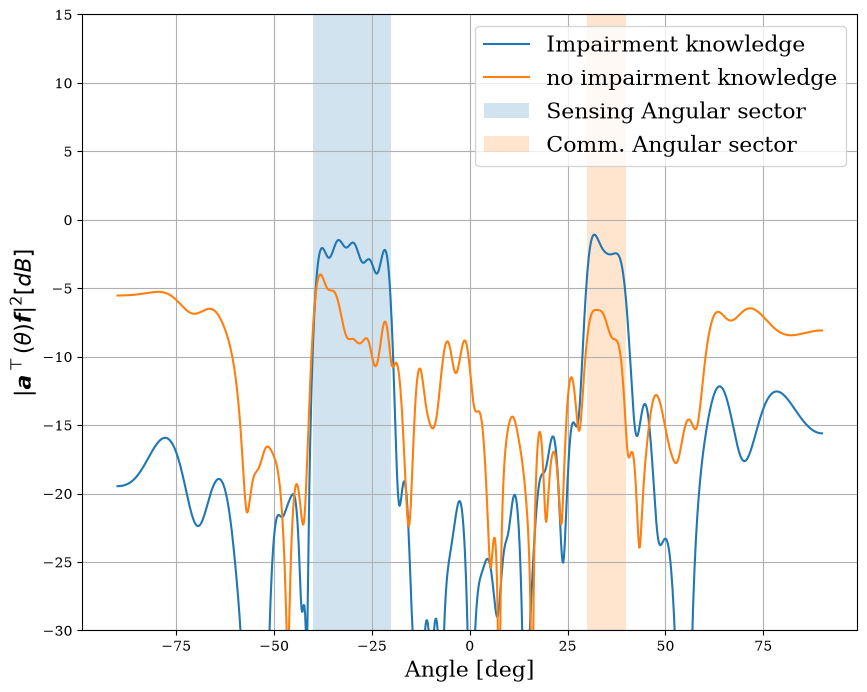

In [5]:
f_true = precoder_isac_true[idx_beam].reshape(-1,1)
f_assumed = precoder_isac_assumed[idx_beam].reshape(-1,1)

# The precoder is radiated through the true (impaired) TX array in both cases
resp_true = 20*torch.log10(torch.abs(A_true_tx.transpose(1,0) @ f_true)).flatten()
resp_assumed = 20*torch.log10(torch.abs(A_true_tx.transpose(1,0) @ f_assumed)).flatten()

theta_grid_deg = theta_grid*180/np.pi
plt.figure(figsize=(10,8))
plt.plot(theta_grid_deg, resp_true, label='Impairment knowledge')
plt.plot(theta_grid_deg, resp_assumed, label='no impairment knowledge')
plt.fill_between([theta_min[idx_beam,0].item()*180/np.pi, theta_max[idx_beam,0].item()*180/np.pi], [-30, -30], [15,15], alpha=0.2, label='Sensing Angular sector')
plt.fill_between([theta_min_comm[idx_beam,0].item()*180/np.pi, theta_max_comm[idx_beam,0].item()*180/np.pi], [-30, -30], [15,15], alpha=0.2, label='Comm. Angular sector')
plt.grid()
plt.xlabel('Angle [deg]', fontsize=16)
plt.ylabel(r'$|\boldsymbol{a}^{\top}(\theta) \boldsymbol{f}|^2 [dB]$', fontsize=16)
plt.legend(fontsize=16)
plt.ylim([-30,15])

np.savetxt("beam_ideal.txt", np.column_stack((theta_grid_deg, resp_true)), fmt="%.6f", delimiter=" ")
np.savetxt("beam_hwi.txt", np.column_stack((theta_grid_deg, resp_assumed)), fmt="%.6f", delimiter=" ")

## Fig. 2: angle-delay maps over the OMP iterations

The dictionaries (15)-(16) use an $N_\theta = N_\tau = 1000$ grid over the sensing angle and range sectors of each batch sample. One OMP iteration per target is run, plus a sixth one on the residual, which only contains noise. Fig. 2a is the first iteration and Fig. 2b the last one; the intermediate iterations also show the estimated target position.

OMP iteration 1
Estimated angle with impairment knowledge (for index 4): tensor([-33.4535])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with impairment knowledge (for index 4): tensor([11.5878])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])
Estimated angle with no impairment knowledge (for index 4): tensor([-33.5736])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with no impairment knowledge (for index 4): tensor([11.6216])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])



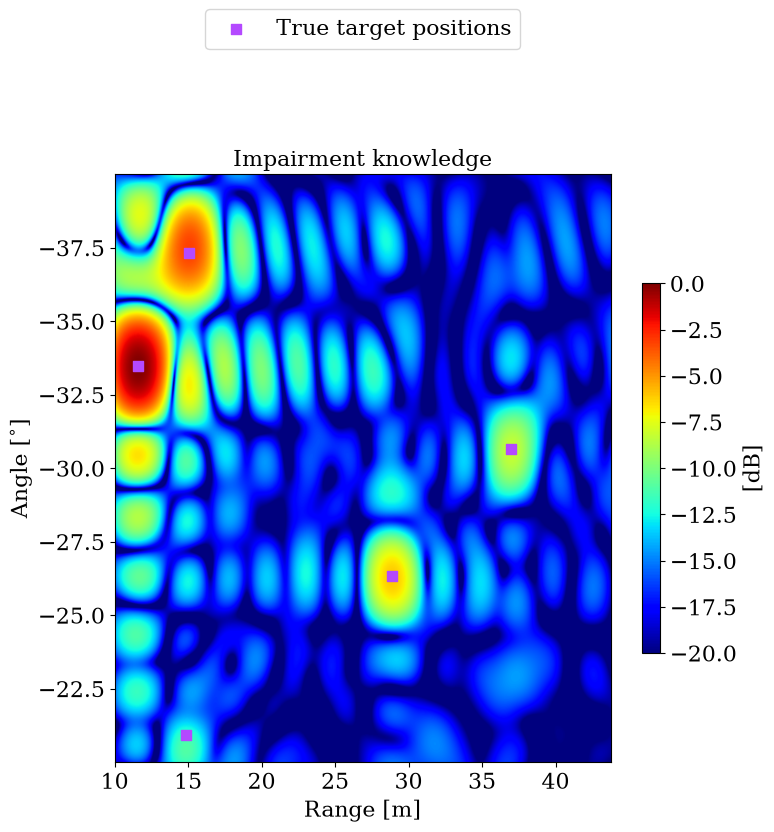

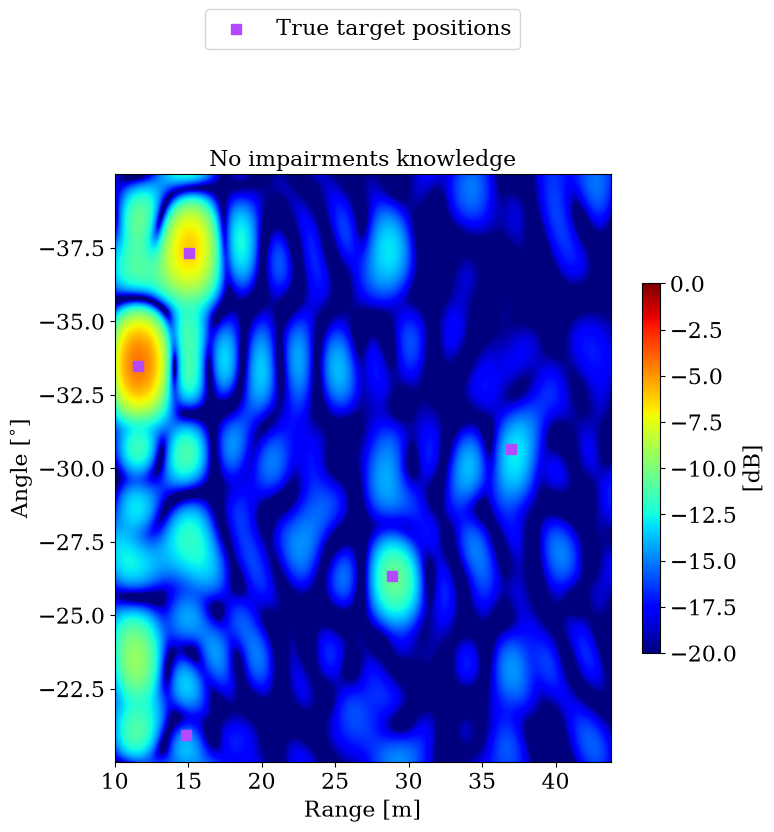

OMP iteration 2
Estimated angle with impairment knowledge (for index 4): tensor([-37.3373])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with impairment knowledge (for index 4): tensor([15.0676])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])
Estimated angle with no impairment knowledge (for index 4): tensor([-37.4374])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with no impairment knowledge (for index 4): tensor([15.0676])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])



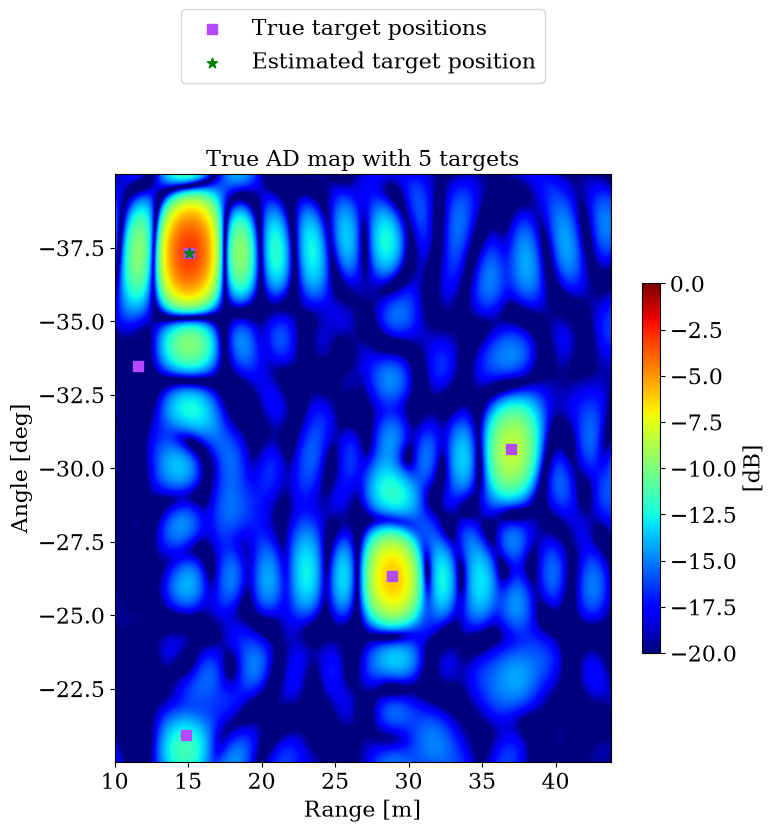

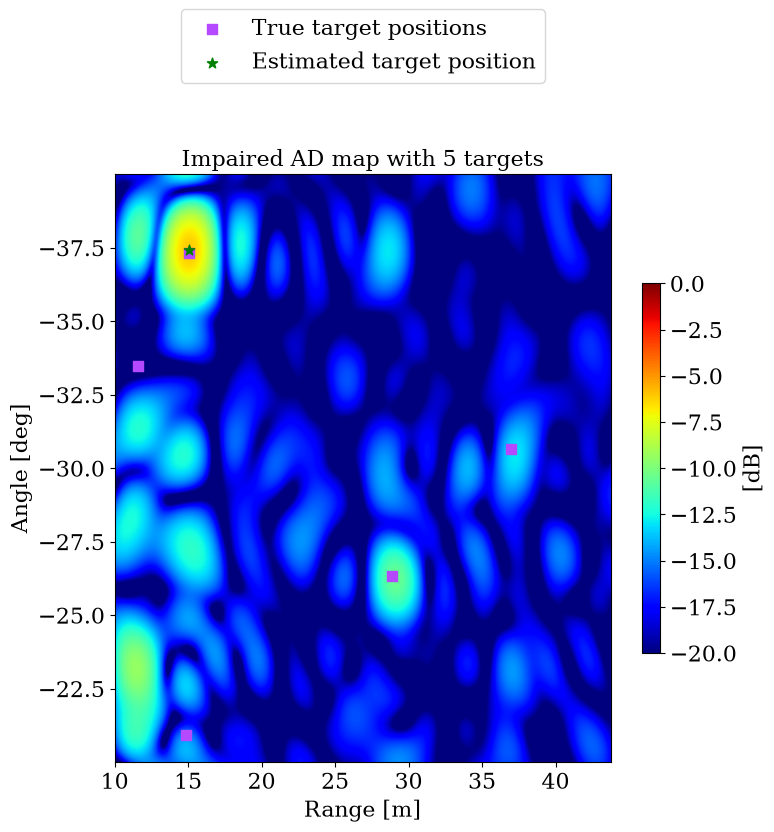

OMP iteration 3
Estimated angle with impairment knowledge (for index 4): tensor([-26.2663])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with impairment knowledge (for index 4): tensor([28.9189])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])
Estimated angle with no impairment knowledge (for index 4): tensor([-23.2032])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with no impairment knowledge (for index 4): tensor([11.4527])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])



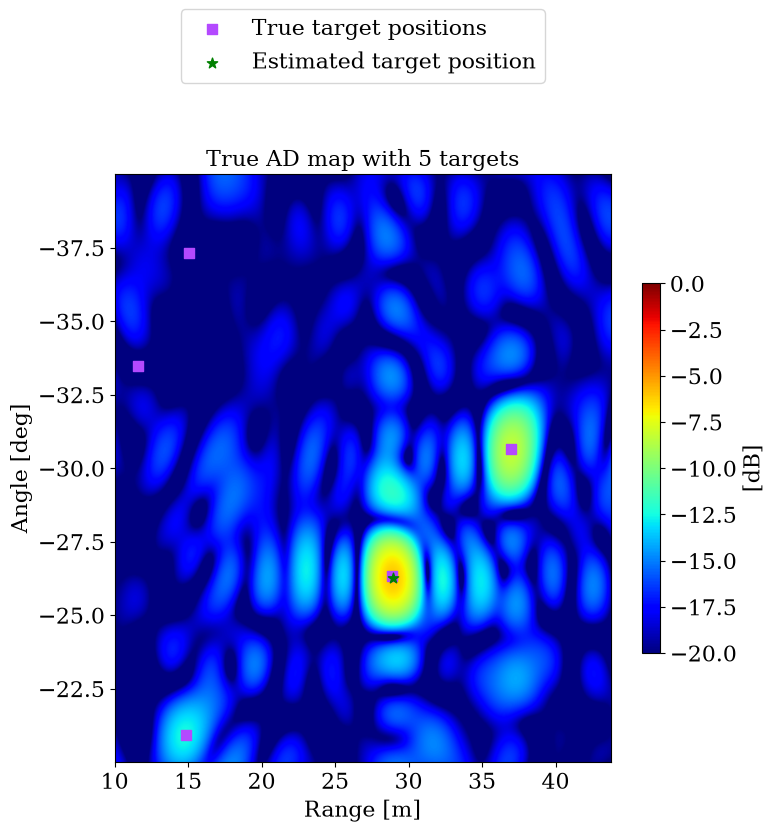

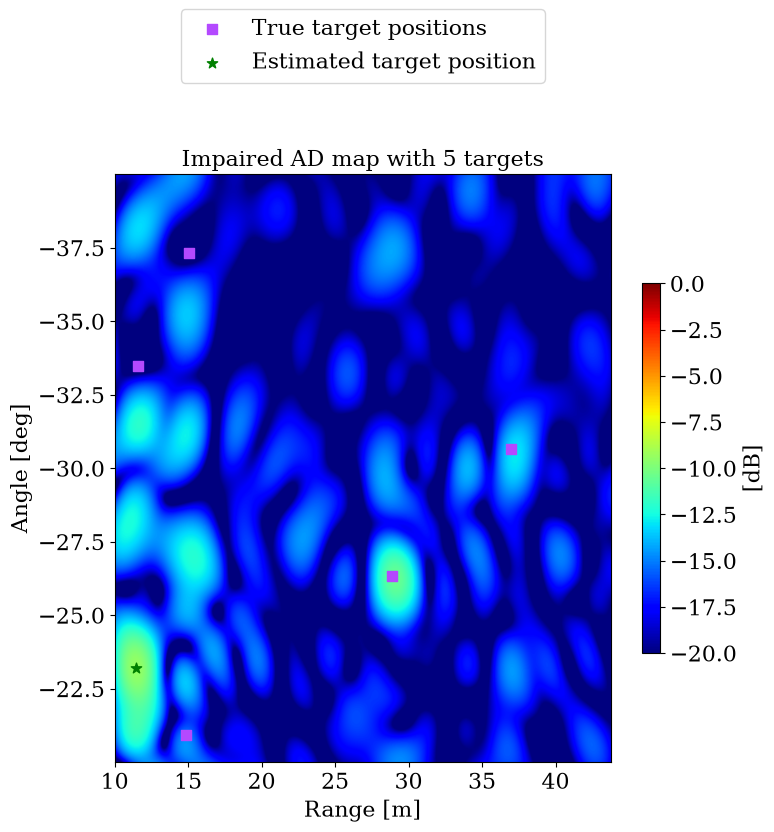

OMP iteration 4
Estimated angle with impairment knowledge (for index 4): tensor([-30.6106])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with impairment knowledge (for index 4): tensor([37.0270])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])
Estimated angle with no impairment knowledge (for index 4): tensor([-26.2262])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with no impairment knowledge (for index 4): tensor([29.1216])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])



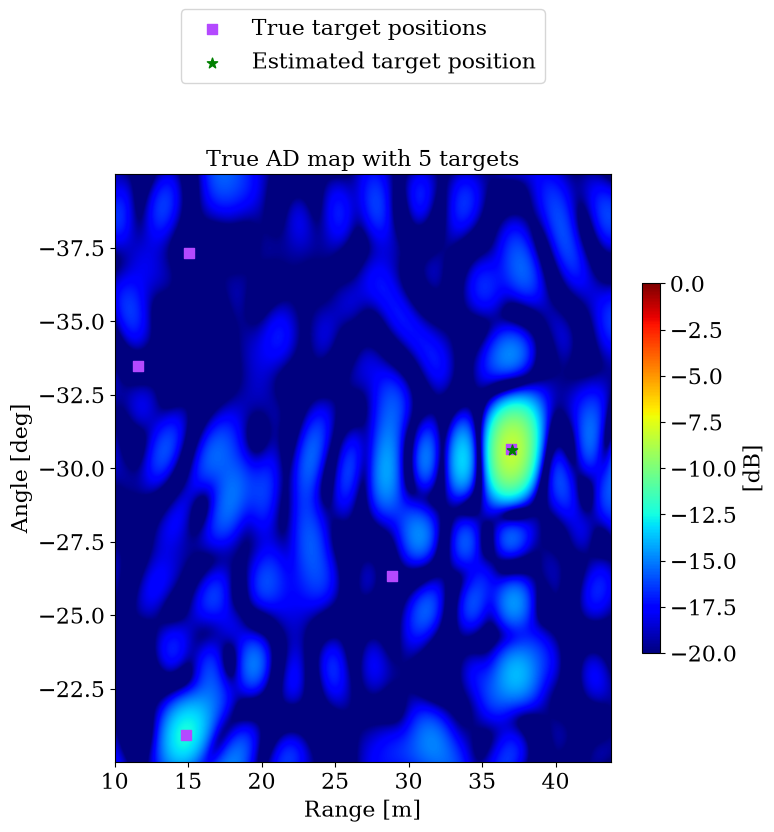

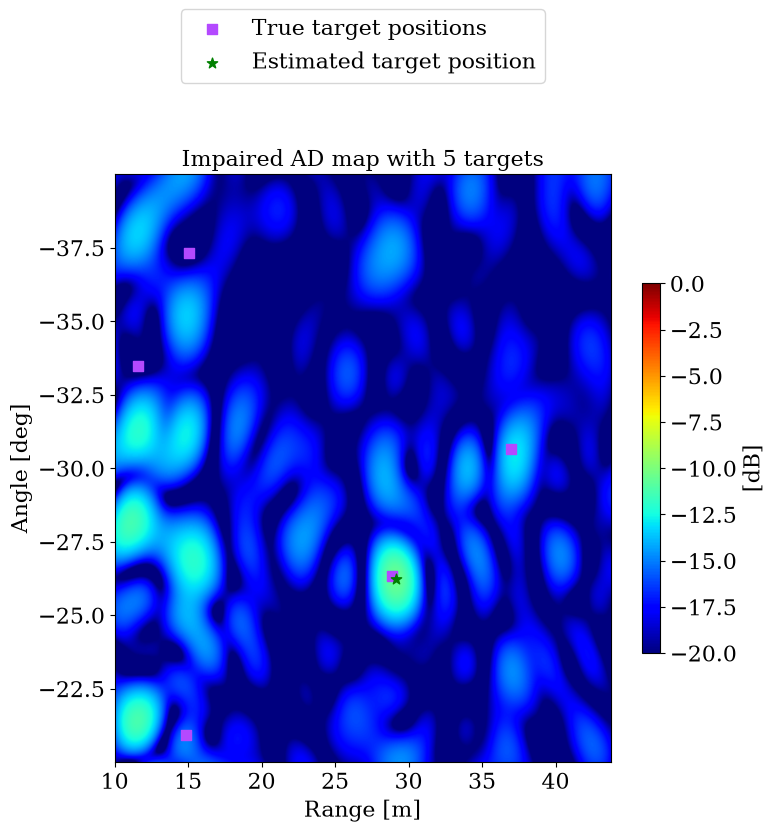

OMP iteration 5
Estimated angle with impairment knowledge (for index 4): tensor([-20.9409])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with impairment knowledge (for index 4): tensor([14.7973])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])
Estimated angle with no impairment knowledge (for index 4): tensor([-21.4014])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with no impairment knowledge (for index 4): tensor([11.5541])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])



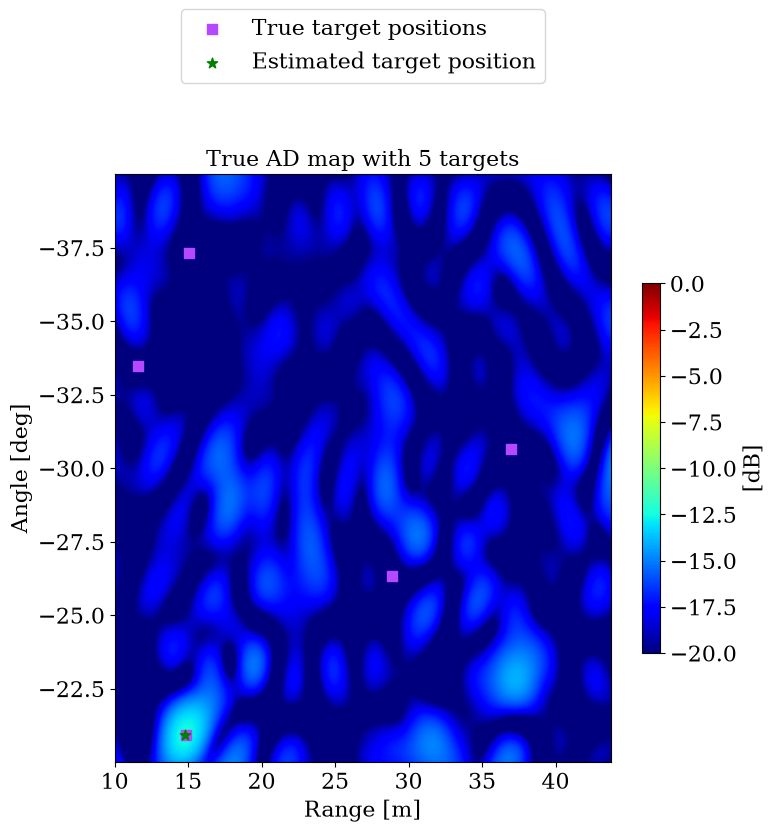

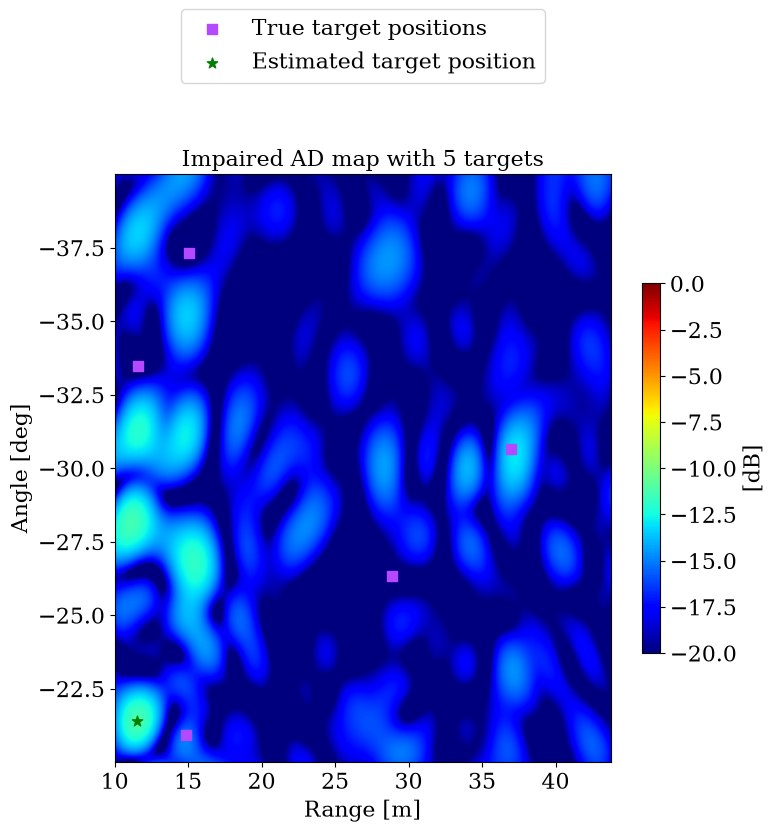

OMP iteration 6
Estimated angle with impairment knowledge (for index 4): tensor([-22.8829])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with impairment knowledge (for index 4): tensor([37.2973])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])
Estimated angle with no impairment knowledge (for index 4): tensor([-28.1882])
True angle (for index 4): tensor([-26.3353, -37.3354, -30.6506, -33.4812, -20.9277])
Estimated range with no impairment knowledge (for index 4): tensor([11.1486])
True range (for index 4): tensor([28.8473, 15.0485, 36.9416, 11.5771, 14.8645])



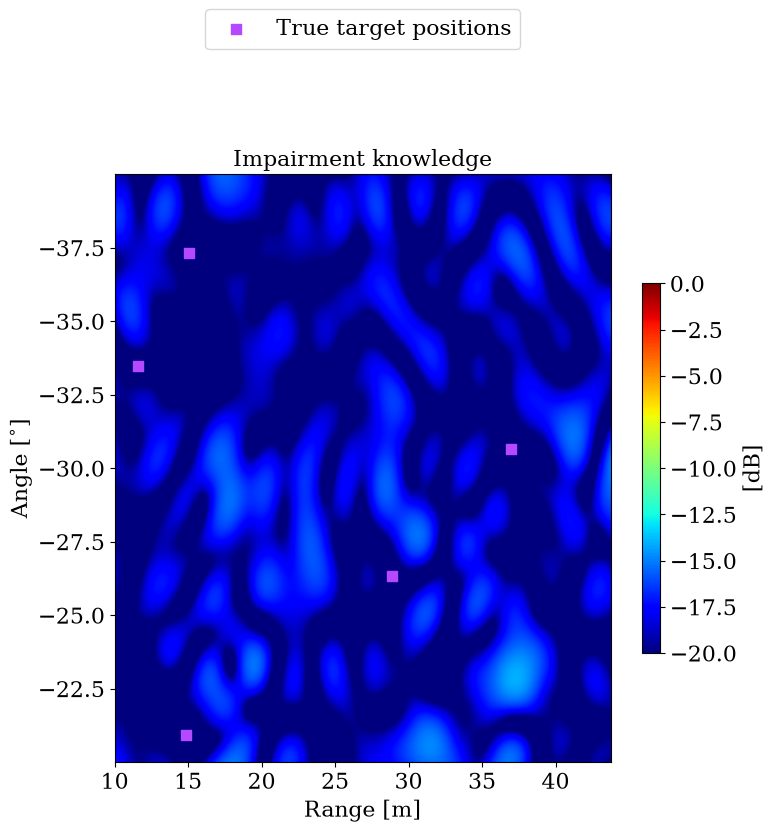

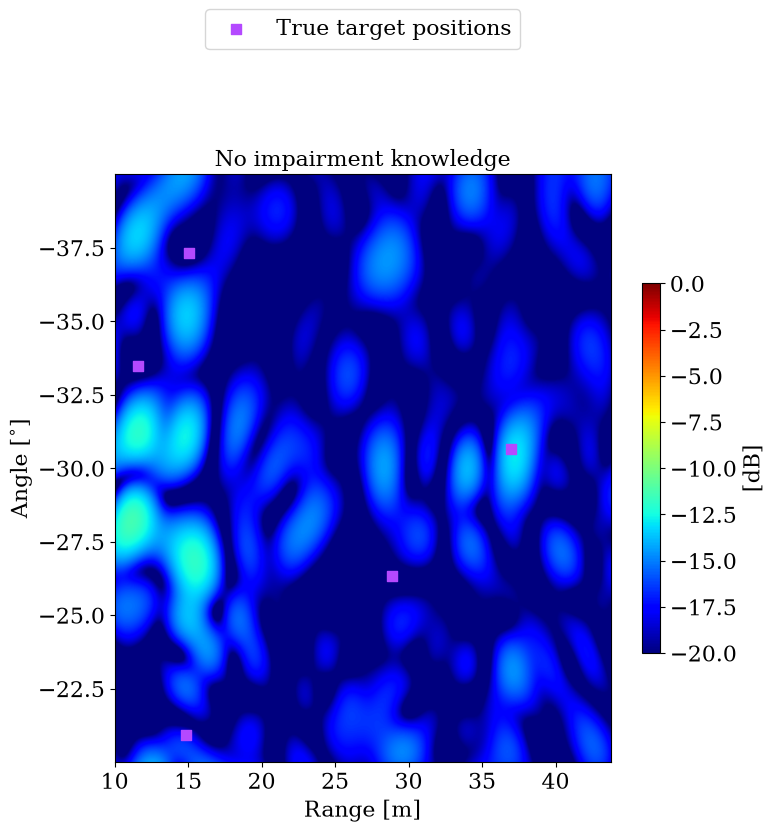

In [6]:
# Angle (15) and delay (16) dictionaries
theta_grid_matrix = uniformGrid(theta_min, theta_max, n_grid)
range_grid_matrix = uniformGrid(r_min, r_max, n_grid)
A_rx_true = angleDictionary(theta_grid_matrix, ant_pos_rx, lamb, true_gp_rx)
A_rx_assumed = angleDictionary(theta_grid_matrix, assumed_pos_rx, lamb, assumed_gp_rx)
P_matrix, _ = delayMatrix(range_grid_matrix, range_grid_matrix, delta_f, n_sub)
P_matrix = P_matrix.transpose(-1,-2).reshape(batch_size, n_grid, n_sub).permute(0,2,1)

# Plot settings of the ADMs of batch sample idx_adm
extent = [r_min[idx_adm].item(), r_max[idx_adm].item(), theta_max[idx_adm].item()*180/np.pi, theta_min[idx_adm].item()*180/np.pi]
tgt_pos = (tgt_range_true[idx_adm], tgt_angle_true[idx_adm]*180/np.pi)
n_omp_it = num_targets + 1

residual_true, residual_assumed = torch.clone(Y_radar_true), torch.clone(Y_radar_assumed)
M_vec_true = torch.zeros((batch_size, n_ant*n_sub, 0), dtype=torch.cfloat, device=device)
M_vec_assumed = torch.clone(M_vec_true)
for it in range(n_omp_it):
    ad_map_true, est_theta_true, est_range_true, M_vec_true, residual_true = ompIteration(
        Y_radar_true, residual_true, M_vec_true, A_rx_true, P_matrix, theta_grid_matrix, range_grid_matrix, delta_f)
    ad_map_assumed, est_theta_assumed, est_range_assumed, M_vec_assumed, residual_assumed = ompIteration(
        Y_radar_assumed, residual_assumed, M_vec_assumed, A_rx_assumed, P_matrix, theta_grid_matrix, range_grid_matrix, delta_f)
    if it == 0:
        max_ad_map_true, _ = torch.max(ad_map_true.reshape((batch_size,-1)),dim=-1)

    print(f'OMP iteration {it+1}')
    printEstimates(idx_adm, est_theta_true, est_range_true, tgt_angle_true, tgt_range_true, 'impairment knowledge')
    printEstimates(idx_adm, est_theta_assumed, est_range_assumed, tgt_angle_true, tgt_range_true, 'no impairment knowledge')
    print()

    # ADMs in dB, normalized to the maximum of the first ADM with impairment knowledge
    ad_map_db_true = 10*torch.log10(ad_map_true[idx_adm]/max_ad_map_true[idx_adm])
    ad_map_db_assumed = 10*torch.log10(ad_map_assumed[idx_adm]/max_ad_map_true[idx_adm])
    if it in (0, n_omp_it-1):
        # Fig. 2a (first iteration) and Fig. 2b (residual)
        fig_name = 'first_it' if it == 0 else 'residual'
        title_assumed = 'No impairments knowledge' if it == 0 else 'No impairment knowledge'
        plotADMap(ad_map_db_true, extent, tgt_pos, 'Impairment knowledge', r'Angle [$^{\circ}$]', file_name=f'{fig_name}_matched.pdf')
        plotADMap(ad_map_db_assumed, extent, tgt_pos, title_assumed, r'Angle [$^{\circ}$]', file_name=f'{fig_name}_mismatched.pdf')
    else:
        plotADMap(ad_map_db_true, extent, tgt_pos, f'True AD map with {num_targets} targets', 'Angle [deg]',
                  est_pos=(est_range_true[idx_adm], est_theta_true[idx_adm]*180/np.pi))
        plotADMap(ad_map_db_assumed, extent, tgt_pos, f'Impaired AD map with {num_targets} targets', 'Angle [deg]',
                  est_pos=(est_range_assumed[idx_adm], est_theta_assumed[idx_adm]*180/np.pi))
    plt.show()